In [42]:
import time

import matplotlib.pyplot as plt

import numpy as np

from scipy.integrate import odeint
from scipy.interpolate import CubicSpline

import pymc as pm
from pymc.ode import DifferentialEquation
import arviz as az

import pytensor
import pytensor.tensor as pt

## Modelo SIR

El modelo SIR es uno de los modelos epidemiológicos más simples capaces de capturar características típicas de los brotes epidémicos. El nombre del modelo proviene de las iniciales:

- $S(t)$: Susceptibles. La fracción o cantidad de individuos sanos en riesgo de contraer el patógeno.
- $I(t)$: Infectados. Individuos que portan la enfermedad y tienen la capacidad de transmitirla al entrar en contacto con la población susceptible.
- $R(t)$: Recuperados (o Removidos). Individuos que ya no participan en la transmisión, ya sea por haber adquirido inmunidad tras la infección o por haber sido aislados.

El modelo relaciona las variaciones de las tres poblaciones a través de la tasa de infección y el período infeccioso promedio. Suponiendo una población total constante: $N = S + I + R$, el modelo SIR viene dado por las siguientes ecuaciones diferenciales:

$$
\begin{align}
\frac{dS}{dt} &= -\frac{\beta}{N} S I \notag\\
\frac{dI}{dt} &= \frac{\beta}{N} S I - \gamma I\\
\frac{dR}{dt} &= \gamma I   \notag
\end{align}
$$

Donde $\beta$ (tasa de transmisión) es la frecuencia de contactos infecciosos por unidad de tiempo y $\gamma$ (tasa de recuperación) es la velocidad a la que los infectados dejan de ser contagiosos. La duración media en la que una persona es potencialmente contagiosa es $D = 1/\gamma$.

Una metrica importante que se puede derivar de los parametros del modelo es el número reproductivo básico (R₀). Este valor representa el promedio de infecciones secundarias que causa una persona contagiosa a lo largo de su periodo infeccioso, dentro de una población totalmente susceptible.

$$R_0 = \frac{\beta}{\gamma}$$

- R₀ > 1: La enfermedad se propaga y genera una epidemia; cada persona contagia a más de un individuo.
- R₀ = 1: La enfermedad se mantiene estable en un nivel endémico.
- R₀ < 1: El brote disminuye y la infección tiende a extinguirse.


In [43]:
def sir_sist(y, t, theta):
    S, I, R = y[0], y[1], y[2]
    beta, gamma = theta[0], theta[1]
    
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

In [44]:
I0, R0 = 1, 0
N = 763
y0 = [N - I0 - R0, I0, R0]

beta = 0.01
gamma = 0.5
args = ((beta, gamma),)

t_eval = np.linspace(0,14,14*5 + 1)

sol = odeint(
    func = sir_sist,
    y0 = y0,
    t = t_eval,
    args = args
    )

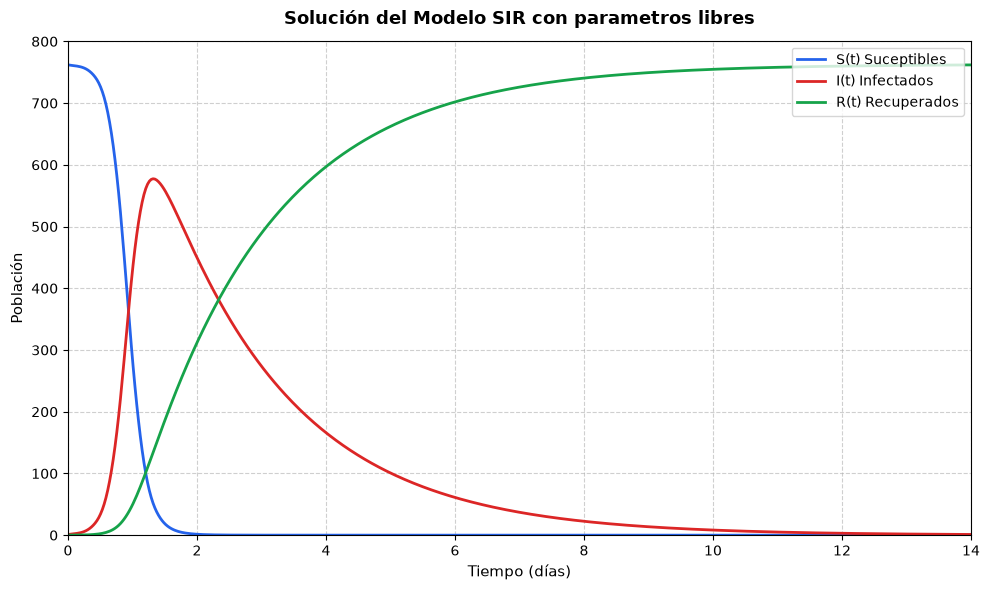

In [45]:
# 1. Puntos temporales donde solve_ivp evaluó la solución
S_pts, I_pts, R_pts = sol.T


# 2. Ajuste de splines cúbicos para cada compartimento
cs_S = CubicSpline(t_eval, S_pts)
cs_I = CubicSpline(t_eval, I_pts)
cs_R = CubicSpline(t_eval, R_pts)


# 3. Malla fina de tiempo para evaluar la interpolación suave
t_fine = np.linspace(t_span[0], t_span[1], 500)
S_spline = cs_S(t_fine)
I_spline = cs_I(t_fine)
R_spline = cs_R(t_fine)

# 4. Graficación
plt.figure(figsize=(10, 6), dpi=100)

# Curvas continuas obtenidas con la interpolación por splines
plt.plot(t_fine, S_spline, label="S(t) Suceptibles", color="#2563eb", lw=2)
plt.plot(t_fine, I_spline, label="I(t) Infectados", color="#dc2626", lw=2)
plt.plot(t_fine, R_spline, label="R(t) Recuperados", color="#16a34a", lw=2)

# Personalización del gráfico
plt.title("Solución del Modelo SIR con parametros libres", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Tiempo (días)", fontsize=11)
plt.ylabel("Población", fontsize=11)
plt.xlim(t_span[0], t_span[1])
plt.ylim(0, N * 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(frameon=True, fontsize=10, loc="upper right")
plt.tight_layout()
plt.show()


## Problema Inverso

Dado un conjunto de datos y un modelo o sistema de simulacion del que (se supone de antemano) provienen dichos datos, el problema inverso consiste en encontrar los parametros que lo definen.

En este caso, se tienen los datos del número de contagiados en un brote de influenza dentro de un internado en Inglaterra.

In [46]:
data = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]
t = np.arange(len(data))
n_poblacion = 763

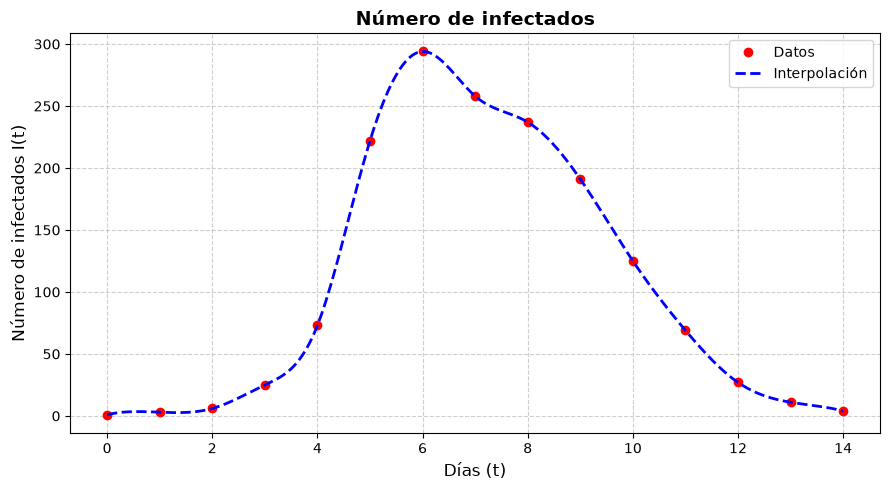

In [47]:
cs = CubicSpline(t, data)

# Generación de puntos densos para graficar la curva suave
t_denso = np.linspace(0,14, 300)
y_spline = cs(t_denso)

# Graficar
plt.figure(figsize=(9, 5))
plt.plot(t, data, "ro", label="Datos", markersize=6)
plt.plot(t_denso, y_spline, "b--", label="Interpolación", linewidth=2)

plt.title("Número de infectados", fontsize=14, fontweight="bold")
plt.xlabel("Días (t)", fontsize=12)
plt.ylabel("Número de infectados I(t)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

El problema entonces consiste en encontrar los parametros $\beta$ y $\gamma$ que mejor se ajusten a los datos observados. Sea $F(t) = (S(t), I(t), R(t))$ la solución al sistema (1), la solución se puede abordar de forma determinista mediante un problema de optimización por mínimos cuadrados o considerar la variación en los datos y abordarlo mediante regresión bayesiana, encontrando una distribución de probabilidad para los parametros.

## Estimación mediante regresión bayesiana

Considerando variaciones aleatorias en los datos, se asume que las observaciones (El numero de infectados $y_i$) proviene de una función determinista $\mu(t_i;\theta)$ (En este caso, $\mu$ es la solución $I$ del modelo epidemiologico) mas un ruido aleatorio $\epsilon_i$

$$y_i = \mu(t; \theta) + \epsilon_i$$

donde $\theta = (\beta, \gamma)$ son los parametros del modelo. 

La estadistica bayesiana asume que los parametros $\theta$ son variables aleatorias con su propia distribucion de probabilidad cada una. Suponiendo una distribucion de probabilidad *a prior* de los parametros, por el teorema de Bayes, la distribucion se puede ajustar o actualizar en funcion de los datos $y$ dados:

$$ P(\theta | y) = \frac{P(y|\theta)P(\theta)}{P(y)}$$

donde

- Distribución a Priori ($P(\theta)$): Representa el conocimiento o suposiciones sobre los parámetros antes de ver los datos como el rango de valores posibles o distribuciones débilmente informativas (ej. $\theta \sim \mathcal{N}(0, 10)$).
- Función de Verosimilitud / Likelihood ($P(y \vert{} \theta)$): Mide qué tan probables son los datos observados si los parámetros $\theta$ tomaran un valor específico. Asumiendo que $\epsilon_i \sim \mathcal{N}(0,\sigma)$, la función de verosimilitud tiene la siguiente forma

    $$
    P(y|\theta) = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(y_i - \mu(x_i; \boldsymbol{\theta}))^2}{2\sigma^2}\right)
    $$

    Si no se tiene un conocimiento previo para definir la desviacion estandar $\sigma$, se agrega como un parametro mas, con su propia distribucion de probabilidad.

- Evidencia o Probabilidad Marginal ($P(y)$): Es la probabilidad total de observar los datos bajo todos los parámetros posibles.
- Distribución a Posteriori ($P(\theta \vert{} y)$): Es la distribución actualizada de los parámetros tras incorporar la evidencia de los datos.


### Distribuciones a priori

Las distribuciones a priori de los parametros se determinaran a partir de la informacion que conocemos de antemano tanto del modelo como de la naturaleza de los datos.

De antemano, tanto $\beta$ como $\gamma$ son estrictamente positivas, por lo que el soporte de sus distribuciones tiene que ser $[0,\infty]$. Para asegurar esta restriccion, los valores a estimar seran los logaritmos de los parametros bajo una probabilidad Normal. Con esto se garantiza que los propios parametros tendran una distribucion Log-Normal, la cual tiene un soporte positivo.

Luego, bajo un brote de influenza en un entorno común, la duración media de infección $\frac{1}{\gamma}$ para un caso de influenza no grave varia entre 3 a 7 dias, por lo que podemos establecer que la media de la distribucion prior del parametro es $\frac{1}{6} \approx 0.1667$, con una desviacion estandar para que la probabilidad se concentre entre esos valores. Por lo que

$$ \log(\gamma) \sim \mathcal{N}(-1.8, 0.2) $$
Fuente: https://www.ncbi.nlm.nih.gov/sites/books/NBK513241/

Por otro lado, la distribucion de $\beta$ se basara en la que tiene el valor $R_0$ al tener una interpretacion mas directa. El numero de reproductivo basico $R_0$, en el caso de la influenza, ronda entre 1 a 3. Pero como los casos se dieron en un ambiente aislado y concentrado (un internado), es posible que este valor este subestimado a los datos. Por lo que la desviacion de la distribucion de $R_0$ sera lo suficientemente grande para que la mayor probabilidad abarque entre 1 a 6.

$$ \log(\beta) \sim \mathcal{N}(-0.4, 0.6) $$





El calculo de la distribucion a posteriori se puede realizar numericamente mediante el metodo de Monte Carlo via cadenas de Markov. Para la implementación de este metodo se recurrirá a la libreria PyMC que ejecuta esta metodologia mediante algoritmo sofisticados (HMC, NUTS, etc.).

In [ ]:
# Definimos el solver que utilizaran los metodos de PyMC para resolver el sistema de edos
ode_model = DifferentialEquation(
    func=sir_sist, 
    times=t_eval[1:], 
    n_states=3, 
    n_theta=2, 
    t0=0
    )